# Bivariate Analysis Of IMDb Dataset

## Objective 

- The objective of this notebook is to perform bivariate analysis on the cleaned IMDb dataset to examine the relationships between pairs of variables and identify patterns, trends, and associations. 
- Both statistical measures and visualizations are used to understand how different movie attributes such as ratings, vote counts, runtime, release year, genre, and metascores relate to one another.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the Cleaned Dataset

The cleaned IMDb dataset was imported for exploratory data analysis and bivariate analysis.

In [4]:
cleaned_data = pd.read_csv("clean_dataset_final.csv")

In [5]:
cleaned_data

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,"['thriller', 'drama', 'crime']",2026,4.5,94.0,TV-MA,NaN,1.3
1,28 Years Later: The Bone Temple,"['thriller', 'sci-fi']",2026,7.3,109.0,R,81.0,88.0
2,3 Body Problem,['fantasy'],2024,7.5,NaN,TV-MA,NaN,180.0
3,56 Days,['romance'],2026,6.7,NaN,TV-MA,NaN,9.6
4,A Big Bold Beautiful Journey,['romance'],2025,6.0,109.0,R,43.0,21.0
...,...,...,...,...,...,...,...,...
250,Young Sherlock,"['action', 'adventure']",2026,7.5,NaN,TV-14,NaN,26.0
251,Your Friends & Neighbors,"['drama', 'crime']",2025,7.7,NaN,TV-MA,NaN,53.0
252,Youth,['romance'],2026,7.1,140.0,Unknown,NaN,6.5
253,Zootopia,['animation'],2016,8.0,108.0,PG,78.0,635.0


In [6]:
import ast
dfb=cleaned_data.copy()
dfb["Genre"]=dfb["Genre"].apply(ast.literal_eval)
dfb=dfb.explode("Genre")
dfb["Genre"]=dfb["Genre"].str.strip()
dfb=dfb.reset_index(drop=True)

In [7]:
dfb.head()

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,thriller,2026,4.5,94.0,TV-MA,NaN,1.3
1,180,drama,2026,4.5,94.0,TV-MA,NaN,1.3
2,180,crime,2026,4.5,94.0,TV-MA,NaN,1.3
3,28 Years Later: The Bone Temple,thriller,2026,7.3,109.0,R,81.0,88.0
4,28 Years Later: The Bone Temple,sci-fi,2026,7.3,109.0,R,81.0,88.0


In [8]:
dfb.describe()

,Year,Rating,Runtime,Metascore,Votes_K
count,495.000000,440.000000,212.000000,166.000000,440.000000
mean,2020.331313,7.590682,124.235849,63.120482,306.723605
std,8.512632,1.084654,31.447105,15.914847,510.937997
min,1972.000000,4.500000,81.000000,33.000000,0.562000
25%,2018.000000,6.900000,104.000000,53.000000,27.000000
50%,2025.000000,7.800000,114.000000,64.000000,128.000000
75%,2026.000000,8.400000,140.000000,73.000000,331.000000
max,2027.000000,9.500000,235.000000,100.000000,2800.000000


## Column Classification

The dataset variables were classified into categorical, numerical, and time-based variables to facilitate appropriate exploratory data analysis techniques.

**Categorical Variables**

- Title (Movie title/identifier)
- Genre
- Certificate

**Numerical Variables**

- Rating
- Runtime (minutes)
- Metascore
- Votes_K (vote count in thousands)

**Time-Based Variable**

- Year


## Separating Numerical and categorical columns

In [9]:
dfb.dtypes

Title           object
Genre           object
Year             int64
Rating         float64
Runtime        float64
Certificate     object
Metascore      float64
Votes_K        float64
dtype: object

In [10]:
numeric_cols = dfb.select_dtypes(include=['float64','int64']).columns   

In [11]:
numeric_cols

Index(['Year', 'Rating', 'Runtime', 'Metascore', 'Votes_K'], dtype='object')

In [12]:
categorical_cols = dfb.select_dtypes(include=['object']).columns

In [13]:
categorical_cols

Index(['Title', 'Genre', 'Certificate'], dtype='object')

# Bivariate Analysis Structure

Bivariate analysis was performed to examine the relationships between pairs of variables in the dataset. Each pair of variables was analyzed using both non-visual and visual techniques to identify patterns, associations, and trends.

1. Non-Visual Analysis

Non-visual analysis focuses on measuring and summarizing relationships between two variables. The following techniques were used:

- Correlation analysis for numerical variables
- Group-wise aggregation and comparison (mean, median, count)
- Cross-tabulation for categorical variables
- Trend analysis across time-based variables
- Comparative statistical summaries across categories
  
2. Visualizations were used to explore relationships and patterns between variables. The following plots were used:

- Scatter plots to examine relationships between numerical variables
- Heatmaps to visualize correlation strength
- Boxplots to compare numerical distributions across categories
- Bar plots to compare aggregated values between groups
- Line plots to analyze trends over time
- Stacked or grouped bar charts for categorical comparisons

This combination of statistical and visual techniques helps identify correlations, differences among groups, and potential factors influencing movie ratings, popularity, runtime, and critic scores.

In [14]:
# if like in table of contents -- for numerical vs numerical eg rating vs votes in that non visual vs visual --will it be too complictaed

# Numerical vs Numerical

## Numerical vs Numerical - Non Visual Analysis

In [15]:
dfb[numeric_cols].corr("kendall")

,Year,Rating,Runtime,Metascore,Votes_K
Year,1.000000,-0.483111,-0.164634,-0.330452,-0.565726
Rating,-0.483111,1.000000,0.418056,0.582534,0.493368
Runtime,-0.164634,0.418056,1.000000,0.332799,0.334630
Metascore,-0.330452,0.582534,0.332799,1.000000,0.371421
Votes_K,-0.565726,0.493368,0.334630,0.371421,1.000000


In [16]:
dfb[numeric_cols].corr("pearson")

,Year,Rating,Runtime,Metascore,Votes_K
Year,1.000000,-0.470911,-0.134579,-0.316273,-0.508975
Rating,-0.470911,1.000000,0.567417,0.745234,0.474254
Runtime,-0.134579,0.567417,1.000000,0.453446,0.328339
Metascore,-0.316273,0.745234,0.453446,1.000000,0.430100
Votes_K,-0.508975,0.474254,0.328339,0.430100,1.000000


In [17]:
dfb[numeric_cols].corr("spearman")

,Year,Rating,Runtime,Metascore,Votes_K
Year,1.000000,-0.627759,-0.213005,-0.419028,-0.743264
Rating,-0.627759,1.000000,0.577683,0.756501,0.662676
Runtime,-0.213005,0.577683,1.000000,0.486631,0.490345
Metascore,-0.419028,0.756501,0.486631,1.000000,0.535293
Votes_K,-0.743264,0.662676,0.490345,0.535293,1.000000


**Observations**

* **Rating and Metascore** show the strongest positive correlation, indicating that highly rated titles generally receive better critic reviews.
* **Rating and Runtime** have a moderate positive relationship, suggesting that longer titles tend to receive slightly higher ratings.
* **Rating and Votes_K** are moderately positively correlated, indicating that highly rated titles often attract more audience engagement.
* **Year** shows a negative correlation with both **Rating** and **Votes_K**, suggesting that older titles generally have higher ratings and more accumulated votes.
* **Runtime and Metascore** exhibit a moderate positive relationship, while **Runtime and Votes_K** show a weak-to-moderate positive association.
* **Metascore and Votes_K** are moderately positively correlated, indicating that critically acclaimed titles tend to attract greater audience attention.
* Similar patterns across **Pearson**, **Spearman**, and **Kendall** correlations suggest consistent relationships among the variables.

**Overall Insight**

> Spearman correlations are generally stronger than Pearson correlations, indicating that many relationships in the dataset are monotonic in nature and not strictly linear.

**Observation**

- The correlation analysis shows both positive and negative relationships among the numerical variables. Most relationships are moderate in strength, while a few variables show strong positive or strong negative correlations.
- Pearson correlation measures linear relationships, Spearman measures monotonic rank relationships, and Kendall measures ordinal association. Similar trends across all three methods indicate consistent relationships among the variables.

**Year vs Other Variables**
- Year shows a negative correlation with almost all other variables, especially with Votes_K and Rating.
- The strongest negative relationship is observed between Year and Votes_K, particularly in Spearman correlation (-0.74), indicating that older titles generally tend to accumulate more votes compared to recently released or upcoming titles.
- Year also shows a moderate negative correlation with Rating, suggesting that newer titles in the dataset tend to have slightly lower ratings compared to older titles.
- This pattern may have occurred because many recent and upcoming titles have not yet accumulated enough audience engagement and reviews.

**Rating vs Metascore**
- Rating and Metascore show the strongest positive correlation across all methods.
Pearson: 0.74
Spearman: 0.75
Kendall: 0.58
- This indicates that titles receiving higher IMDb audience ratings also tend to receive higher critic metascores.
- The strong positive relationship suggests consistency between audience reception and critic evaluation.

**Rating vs Runtime**
- Runtime shows a moderate positive correlation with Rating.
Pearson: 0.56
Spearman: 0.57
Kendall: 0.41
- This suggests that longer-duration titles tend to receive slightly higher ratings on average.
- However, the relationship is moderate rather than strong, meaning runtime alone does not fully determine audience ratings.

**Rating vs Votes_K**
- Rating and Votes_K display a moderate positive correlation.Pearson: 0.47,Spearman: 0.66,Kendall: 0.49
- This indicates that highly rated titles generally attract higher audience engagement and vote counts.
- The stronger Spearman correlation suggests that the ranking relationship between ratings and votes is stronger than the purely linear relationship.

**Runtime vs Metascore**
- Runtime and Metascore show a moderate positive relationship.
- Titles with longer runtimes tend to receive slightly better critic scores, although the relationship is not extremely strong.

**Runtime vs Votes_K**
- Runtime and Votes_K show a weak-to-moderate positive correlation.
- Longer titles appear to receive somewhat higher audience engagement, but the relationship remains moderate.

**Metascore vs Votes_K**
- Metascore and Votes_K show a moderate positive correlation.
- Titles receiving better critic reviews generally tend to attract more audience attention and voting activity.

**Interpretation of Different Correlation Methods**
1.Pearson Correlation- Measures linear relationships between variables.
2.Spearman Correlation-Measures monotonic rank-based relationships and is less sensitive to outliers.
3.Kendall Correlation- Measures ordinal association and is generally more conservative.

**IMPORTANT OVERALL INSIGHT**

>Spearman correlations are generally stronger than Pearson correlations in this dataset. This suggests that several relationships are monotonic but not perfectly linear, and that ranking-based relationships are more prominent than strictly linear relationships.

## Numerical vs Numerical - Visual Analysis

In [18]:
# PLots- line plot, scatter plot
numeric_cols

Index(['Year', 'Rating', 'Runtime', 'Metascore', 'Votes_K'], dtype='object')

#### Year vs Rating

In [19]:
# Year vs Rating, Rating vs Votes,Metascore vs Votes
# Rating vs Metascore

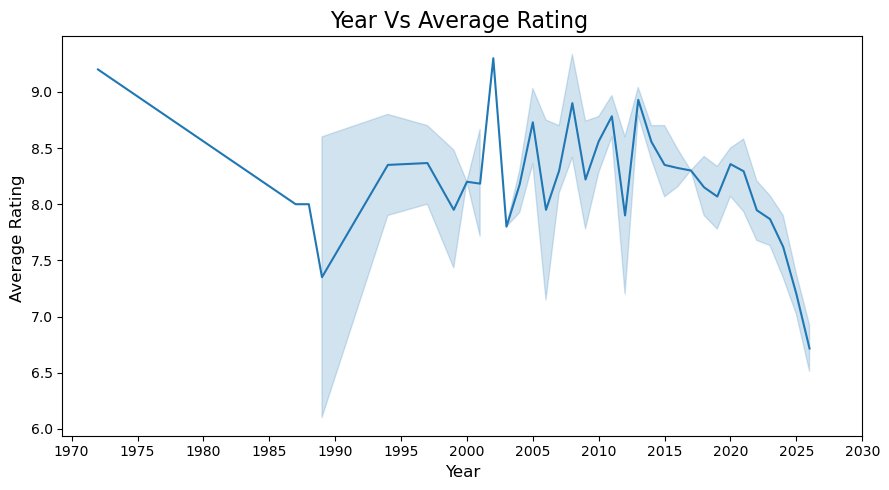

In [20]:
plt.figure(figsize=(9,5))
plt.title("Year Vs Average Rating ",fontsize=16)
sns.lineplot(data=dfb,x="Year",y="Rating")
plt.xticks(range(1970,2031,5))
plt.xlabel("Year",fontsize=12)
plt.ylabel("Average Rating ",fontsize=12)
plt.tight_layout()
plt.show()

**Observations**

* The plot shows the average IMDb rating by release year.
* Ratings fluctuate across years rather than following a consistent increasing or decreasing trend.
* Most years have average ratings between 7.5 and 8.8, indicating generally well-rated titles.
* A few years show exceptionally high average ratings, but these may be influenced by a small number of titles.
* Average ratings appear to decline slightly in recent years (2025–2027).
* The dataset is heavily concentrated in 2025 and 2026, so recent years have a greater influence on the overall trend.
* Ratings should be interpreted alongside Votes_K, as ratings based on a larger number of votes are generally more reliable.
* Overall, the plot suggests a moderate negative relationship between Year and Rating, which supports the correlation analysis.
  
**Conclusion**

>Newer titles in the dataset tend to have slightly lower average ratings than older titles, although the trend should be interpreted cautiously due to the uneven distribution of titles across years and differences in vote counts.

#### Rating vs Votes_K

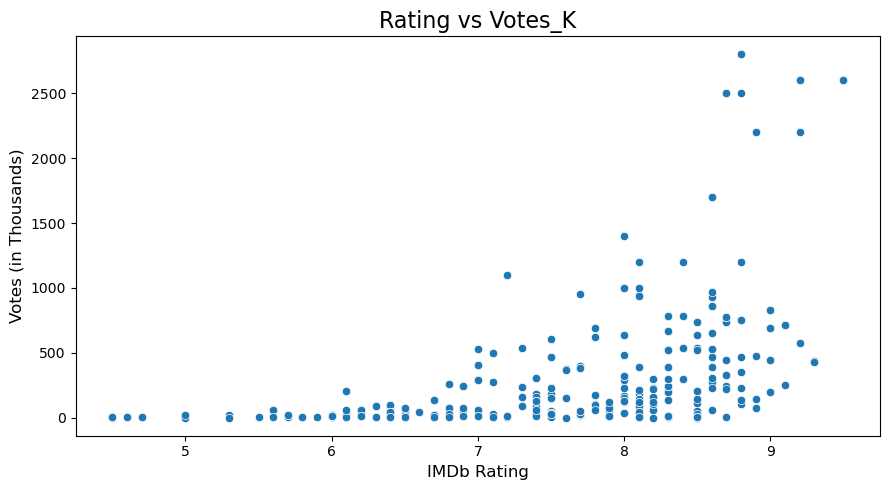

In [21]:
plt.figure(figsize=(9,5))
sns.scatterplot(data=dfb, x="Rating", y="Votes_K")
plt.title("Rating vs Votes_K",fontsize=16)
plt.xlabel("IMDb Rating",fontsize=12)
plt.ylabel("Votes (in Thousands)",fontsize=12)
plt.tight_layout()
plt.show()

**Observations: Rating vs Votes_K (Scatter Plot)**

* The scatter plot shows a moderate positive relationship between IMDb Rating and Votes_K.
* In general, titles with higher ratings tend to attract a larger number of audience votes.
* Most titles are concentrated in the rating range of 7 to 9, indicating that the majority of movies/shows in the dataset are fairly well-rated.
* A few titles have exceptionally high vote counts (above 2000K votes), appearing as outliers in the dataset.
* The spread of vote counts increases as ratings increase, suggesting that highly rated titles can vary greatly in popularity.
* While higher-rated titles generally receive more votes, the relationship is not perfect. Some titles with similar ratings have significantly different vote counts.
* The presence of several high-vote outliers contributes to the positive correlation observed between Rating and Votes_K.
  
**Conclusion**

>The scatter plot indicates a moderate positive association between IMDb ratings and audience engagement. Titles with higher ratings tend to receive more votes, suggesting that well-received content often attracts greater audience attention and participation.



#### Metascore vs Votes_K

<Figure size 900x500 with 0 Axes>

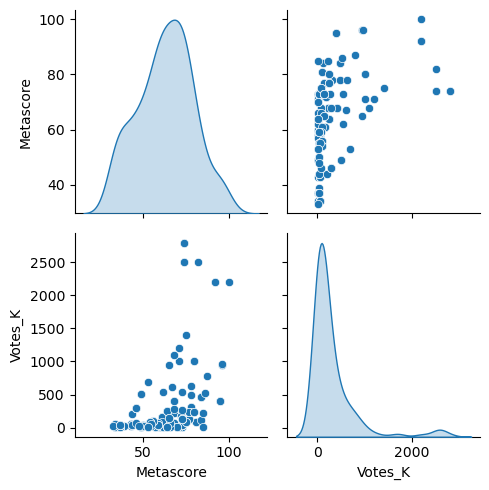

In [22]:
plt.figure(figsize=(9,5))
# plt.title("Metascore vs Votes(in K)",fontsize=16)
sns.pairplot(dfb[["Metascore","Votes_K"]], diag_kind="kde")
plt.tight_layout()
plt.show()

**Motto :- "Do movies/shows that receive better critic reviews attract more audience attention?"**

**Observations: Metascore vs Votes_K (Pairplot)**

Distribution Analysis
* The KDE plot for Metascore shows that most titles have metascores between 50 and 80, with a peak around 60–70.
* The KDE plot for Votes_K is highly right-skewed, indicating that most titles receive relatively low vote counts, while a few titles receive exceptionally high audience engagement.
  
Relationship Analysis
* The scatterplots suggest a moderate positive relationship between Metascore and Votes_K.
* Titles with higher metascores generally tend to attract more audience votes.
* Most titles are concentrated in the range of 40–80 Metascore and below 500K votes.
* Several outliers are present with very high vote counts (above 2000K votes), indicating extremely popular titles.
* The relationship is not perfectly linear, as titles with similar metascores can have significantly different vote counts.
  
**Conclusion**

>The pairplot indicates a moderate positive association between critic reviews (Metascore) and audience engagement (Votes_K). Titles receiving better critic scores tend to attract more audience attention, although critic ratings alone do not fully determine a title's popularity.


# Categorical vs Categorical

In [23]:
# Genre,Year,Certificate
categorical_cols

Index(['Title', 'Genre', 'Certificate'], dtype='object')

### Categorical vs Categorical - Non Visual Analysis

#### Genre vs Year

In [24]:
c1=pd.crosstab(dfb["Genre"],dfb["Year"])
print(c1)

Year       1972  1987  1988  1989  1994  1997  1999  2000  2001  2002  ...  \
Genre                                                                  ...   
action        0     0     0     0     0     0     0     0     0     0  ...   
adventure     0     0     0     0     0     0     1     0     2     0  ...   
animation     0     0     1     1     0     1     1     0     1     0  ...   
comedy        0     0     0     1     0     0     0     1     0     0  ...   
crime         1     0     0     0     0     0     2     0     0     1  ...   
drama         0     0     0     0     1     0     0     1     0     0  ...   
fantasy       0     0     0     0     0     0     1     0     2     0  ...   
romance       0     1     0     0     3     2     0     0     0     0  ...   
sci-fi        0     0     0     0     0     0     0     0     1     0  ...   
thriller      0     0     0     0     0     0     1     0     0     0  ...   

Year       2018  2019  2020  2021  2022  2023  2024  2025  2026

**Observations (Genre vs Year Crosstab)**
* The crosstab shows the frequency distribution of each genre across different release years.
* Most genres have a higher number of titles in 2025 and 2026 compared to earlier years.
* Older years contain relatively few titles across all genres.
* The distribution of genres is not uniform across years, indicating a temporal imbalance in the dataset.
* The crosstab serves as the basis for the heatmap visualization, which provides a clearer view of these patterns.

#### Year vs Certificate

In [25]:
c2=pd.crosstab(dfb["Year"],dfb["Certificate"])
print(c2)

Certificate  G  PG  PG-13   R  TV-14  TV-MA  TV-PG  TV-Y7-FV  Unknown
Year                                                                 
1972         0   0      0   1      0      0      0         0        0
1987         0   1      0   0      0      0      0         0        0
1988         0   0      0   1      0      0      0         0        0
1989         0   0      0   1      1      0      0         0        0
1994         0   0      1   0      3      0      0         0        0
1997         0   0      1   1      0      1      0         0        0
1999         0   0      2   0      2      2      0         0        0
2000         0   0      0   0      0      0      2         0        0
2001         0   2      2   0      0      0      2         0        0
2002         0   0      0   0      0      1      0         0        0
2003         0   0      0   0      4      0      0         0        0
2004         0   0      1   0      3      0      0         0        0
2005         0   0  

**Observations (Year vs Certificate Crosstab)**
* The distribution of certificates varies across release years.
* TV-MA is the most common certificate in many recent years, particularly from 2013 onwards.
* R and PG-13 certifications become more prominent in 2025 and 2026.
* The Unknown certificate category is concentrated almost entirely in 2025–2027, suggesting that certification information was unavailable for several recently released or upcoming titles.
* Older years contain relatively few observations, making it difficult to identify strong certification patterns for those periods.
* Family-friendly certifications such as G and TV-Y7-FV occur very rarely in the dataset.
  
**Conclusion**

>The crosstab indicates that mature audience certifications, especially TV-MA, dominate the dataset across recent years. However, interpretations should be made cautiously because the dataset is heavily concentrated in 2025 and 2026, while earlier years contain relatively few titles.

#### Genre vs Certificate

In [26]:
c3=pd.crosstab(dfb["Genre"],dfb["Certificate"])
print(c3)

Certificate  G  PG  PG-13   R  TV-14  TV-MA  TV-PG  TV-Y7-FV  Unknown
Genre                                                                
action       0   2      4  13      7     12      1         1        9
adventure    0   5     11   4      5     11      2         1       10
animation    2  13      2   1     10     14      5         1        2
comedy       0   5      6  12      7     12      1         0        6
crime        0   1      2   9     12     22      1         0        3
drama        0   0      3   8      8     27      1         0        3
fantasy      0   5      7   4      7     14      2         1        8
romance      0   1     10   8      8     12      3         0        8
sci-fi       0   1      9   9      3     18      2         0        8
thriller     0   0      2  19      6     17      0         0        6


In [27]:
pd.crosstab(
    dfb["Genre"],
    dfb["Certificate"],
    normalize="index"
) * 100

# Try margins=True

Certificate,G,PG,PG-13,R,TV-14,TV-MA,TV-PG,TV-Y7-FV,Unknown
Genre,,,,,,,,,
action,0.0,4.081633,8.163265,26.530612,14.285714,24.489796,2.040816,2.040816,18.367347
adventure,0.0,10.204082,22.448980,8.163265,10.204082,22.448980,4.081633,2.040816,20.408163
animation,4.0,26.000000,4.000000,2.000000,20.000000,28.000000,10.000000,2.000000,4.000000
comedy,0.0,10.204082,12.244898,24.489796,14.285714,24.489796,2.040816,0.000000,12.244898
crime,0.0,2.000000,4.000000,18.000000,24.000000,44.000000,2.000000,0.000000,6.000000
drama,0.0,0.000000,6.000000,16.000000,16.000000,54.000000,2.000000,0.000000,6.000000
fantasy,0.0,10.416667,14.583333,8.333333,14.583333,29.166667,4.166667,2.083333,16.666667
romance,0.0,2.000000,20.000000,16.000000,16.000000,24.000000,6.000000,0.000000,16.000000
sci-fi,0.0,2.000000,18.000000,18.000000,6.000000,36.000000,4.000000,0.000000,16.000000


**Motto:- For each Genre, what percentage of titles belong to each Certificate?**

**Observations (Genre vs Certificate - Percentage Distribution)**

* TV-MA is the most common certification across most genres, accounting for 24%–54% of titles depending on the genre.
* Drama has the highest proportion of TV-MA content (54%), indicating a strong concentration of mature-audience titles.
* Crime also shows a high percentage of TV-MA content (44%), followed by Sci-Fi (36%) and Thriller (34%).
* Thriller has the highest proportion of R-rated titles (38%), suggesting that this genre frequently contains mature themes.
* Animation stands out from other genres, with a higher share of family-friendly certifications such as PG (26%), TV-PG (10%), and G (4%).
* Adventure, Romance, and Sci-Fi contain relatively larger proportions of PG-13 content compared to other genres.
* The Unknown category is present across several genres, particularly Adventure (20.4%), Action (18.4%), Fantasy (16.7%), and Sci-Fi (16%), indicating missing certification information for a notable number of titles.
* Family-oriented certifications (G and TV-Y7-FV) are rare across the dataset and appear primarily in Animation-related content.
  
**Conclusion**

>The percentage distribution shows that mature-audience certifications (TV-MA and R) dominate most genres in the dataset. Animation is the primary exception, exhibiting a larger share of family-friendly certifications. Overall, the dataset contains a strong concentration of content targeted toward teen and adult audiences.

### Categorical vs Categorical - Visual Analysis

In [28]:
# plot - violin , catplot,heatmap,clustermap
# Genre , Certificate and Year ---Title cannot be used as it is unique 

In [29]:
categorical_cols

Index(['Title', 'Genre', 'Certificate'], dtype='object')

#### Genre vs Year

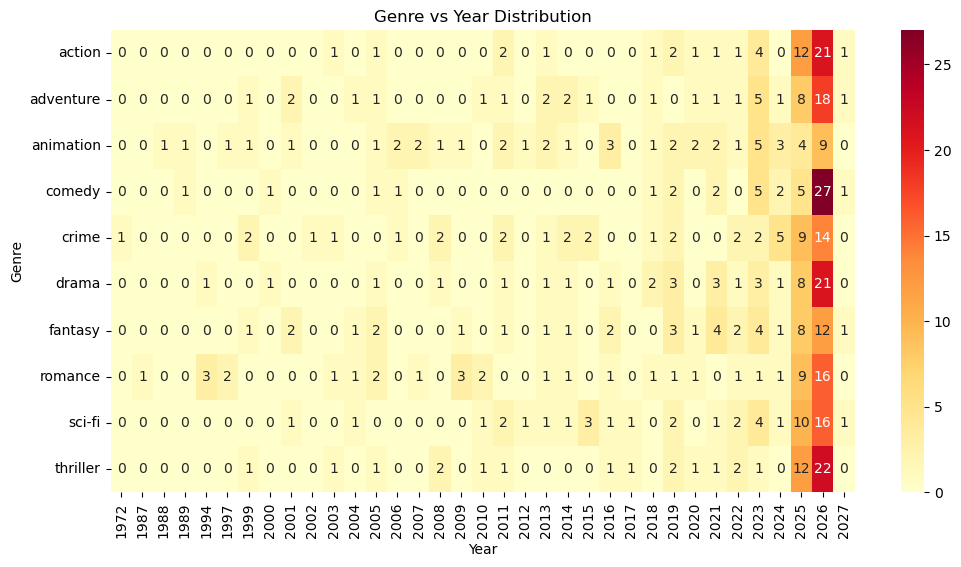

In [30]:
plt.figure(figsize=(12,6))
sns.heatmap(c1, annot=True, cmap="YlOrRd")
plt.title("Genre vs Year Distribution")
plt.xlabel("Year")
plt.ylabel("Genre")
plt.show()

**Observations: Genre vs Year (Heatmap)**

* The heatmap shows the frequency distribution of genres across different release years.
* Most genres have a significantly higher concentration of titles in 2025 and 2026, indicating that the dataset is heavily skewed toward recent releases.
* Older years contain very few titles across all genres, which is reflected by the darker color intensity in those periods.
* Drama, Crime, Thriller, Romance, and Sci-Fi appear more frequently in recent years compared to some other genres.
* The brighter cells in 2025 and 2026 suggest that these years contribute a large proportion of the observations in the dataset.
* No single genre completely dominates across all years; however, the distribution is clearly concentrated in the most recent years.
* The heatmap confirms the imbalance observed during univariate analysis, where recent years had substantially more records than earlier years.

**Conclusion**

>The Genre vs Year heatmap indicates that the dataset is heavily concentrated in recent years, particularly 2025 and 2026. 
While all genres are represented, their occurrences are not evenly distributed across years, and recent releases contribute the majority of the records.

In [31]:
# plt.figure(figsize=(12,6))
# sns.heatmap(c2, annot=True, cmap="YlOrRd")
# plt.title("Certificate vs Year Distribution")
# plt.xlabel("Certificate")
# plt.ylabel("Year")
# plt.show()

#### Genre vs Certificate

<Figure size 900x500 with 0 Axes>

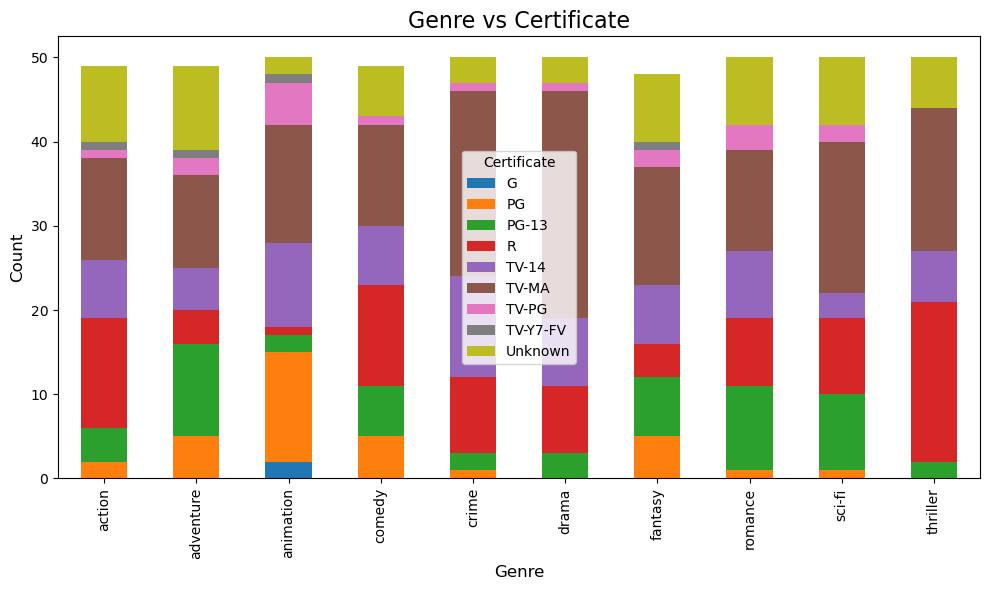

In [33]:
plt.figure(figsize=(9,5))
c3.plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Genre vs Certificate",fontsize=16)
plt.xlabel("Genre",fontsize=12)
plt.ylabel("Count",fontsize=12)
plt.tight_layout()
plt.show()

# add percentages??

**Observations: Genre vs Certificate (Stacked Bar Chart)**

* TV-MA is the most dominant certificate across almost all genres, indicating that a large proportion of the titles in the dataset are intended for mature audiences.
* R-rated content is also common across several genres, particularly Thriller, Crime, Drama, and Action.
* PG-13 titles are distributed across most genres and are especially visible in Adventure, Fantasy, Romance, and Sci-Fi.
* Animation contains a relatively higher proportion of PG and family-friendly certifications compared to other genres.
* TV-Y7-FV and G certificates appear very rarely, indicating limited children's content in the dataset.
* The Unknown category is present across multiple genres, suggesting that certification information was unavailable for some titles during data extraction.
* Crime, Drama, Thriller, and Romance have a larger share of mature audience certifications (TV-MA and R), while Animation tends to have more family-oriented certifications.
  
**Conclusion**

>The stacked bar chart shows that mature audience certifications, particularly TV-MA and R, dominate most genres in the dataset. Family-friendly certifications such as G, PG, and TV-Y7-FV are comparatively less common and are primarily associated with Animation and a few Adventure/Fantasy titles.

In [34]:
# sns.violinplot(data=dfb,x="Title",y="Certificate")

In [35]:
# sns.catplot(data=dfb,x="Genre",y="Certificate")

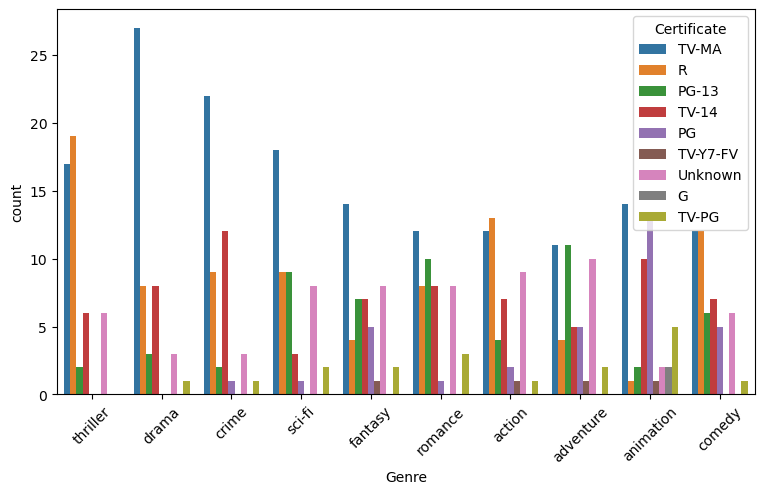

In [36]:
plt.figure(figsize=(9,5))
sns.countplot(
    data=dfb,
    x="Genre",
    hue="Certificate"
)

plt.xticks(rotation=45)
plt.show()

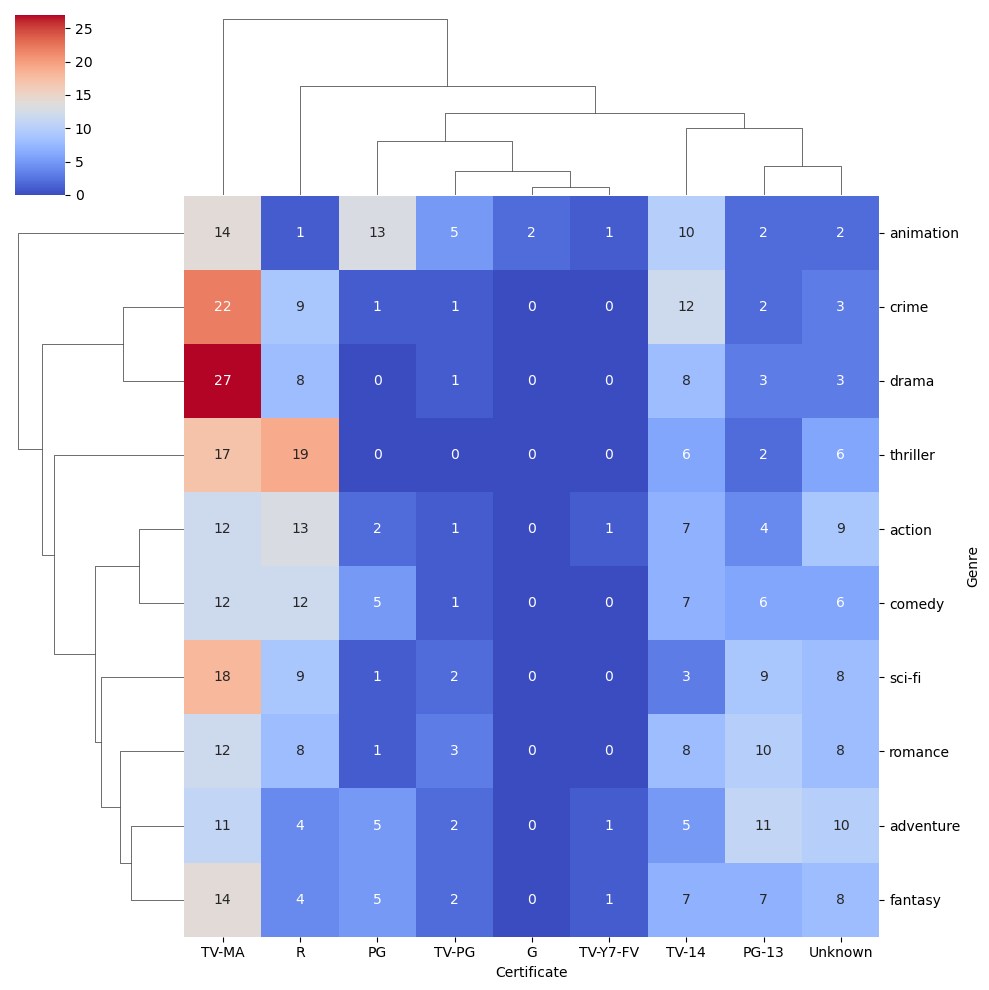

In [37]:
cl=pd.crosstab(dfb["Genre"],dfb["Certificate"])
sns.clustermap(cl, cmap="coolwarm",annot=True)

# Numerical vs Categorical

Check here as lot od suplicate code as well as multivariate code is present

In [38]:
dfb.columns

Index(['Title', 'Genre', 'Year', 'Rating', 'Runtime', 'Certificate',
       'Metascore', 'Votes_K'],
      dtype='object')

### Numerical vs Categorical - Non Visual Analysis

In [39]:
dfb.describe(include="all")

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
count,495,495,495.000000,440.000000,212.000000,495,166.000000,440.000000
unique,255,10,NaN,NaN,NaN,9,NaN,NaN
top,Invincible,thriller,NaN,NaN,NaN,TV-MA,NaN,NaN
freq,7,50,NaN,NaN,NaN,159,NaN,NaN
mean,NaN,NaN,2020.331313,7.590682,124.235849,NaN,63.120482,306.723605
std,NaN,NaN,8.512632,1.084654,31.447105,NaN,15.914847,510.937997
min,NaN,NaN,1972.000000,4.500000,81.000000,NaN,33.000000,0.562000
25%,NaN,NaN,2018.000000,6.900000,104.000000,NaN,53.000000,27.000000
50%,NaN,NaN,2025.000000,7.800000,114.000000,NaN,64.000000,128.000000
75%,NaN,NaN,2026.000000,8.400000,140.000000,NaN,73.000000,331.000000


In [40]:
dfb.columns

Index(['Title', 'Genre', 'Year', 'Rating', 'Runtime', 'Certificate',
       'Metascore', 'Votes_K'],
      dtype='object')

In [41]:
print(categorical_cols)

Index(['Title', 'Genre', 'Certificate'], dtype='object')


#### Genre vs Rating

In [42]:
dfb.groupby("Genre")["Rating"].agg(
    ["count","mean","median","min","max"]
)

,count,mean,median,min,max
Genre,,,,,
action,39,7.520513,7.70,4.6,9.3
adventure,38,7.839474,8.15,5.6,9.3
animation,47,8.187234,8.50,5.5,9.3
comedy,46,7.021739,7.15,4.5,9.0
crime,49,7.646939,7.80,4.5,9.5
drama,47,7.610638,7.90,4.5,9.5
fantasy,38,7.934211,8.10,6.1,9.3
romance,49,7.373469,7.60,5.3,8.8
sci-fi,40,7.790000,8.00,5.7,9.0


**Observations: Genre vs Rating**
- Animation has the highest average rating (8.19) and median rating (8.50), indicating that animated titles in the dataset are generally very well received by audiences.
- Fantasy (7.93) and Adventure (7.84) also have relatively high average ratings, suggesting strong audience appreciation for these genres.
- Comedy has the lowest average rating (7.02) and a median rating of 7.15, making it the lowest-rated genre in the dataset.
- Thriller (7.11) and Romance (7.37) also have comparatively lower average ratings than other genres.
- The highest rating observed in the dataset is 9.5, achieved by titles belonging to Crime, Drama, and Thriller genres.
- The lowest ratings (4.5) are observed in Comedy, Crime, Drama, and Thriller, indicating the presence of some poorly rated titles in these genres.
- Most genres have median ratings close to or above 7.5, suggesting that the majority of titles in the dataset are generally well-rated.
- The number of observations is fairly balanced across genres (ranging from 38 to 49 titles), making the comparison of average ratings reasonably reliable.
  
**Conclusion**
>The analysis indicates that Animation, Fantasy, and Adventure tend to receive higher audience ratings, whereas Comedy, Thriller, and Romance have comparatively lower average ratings. However, all genres maintain average ratings above 7, suggesting that the overall quality of titles in the dataset is relatively high.
Mean ≈ Median
The rating distributions within genres are not extremely skewed, and the median ratings are generally close to the mean ratings.

#### Certificate vs Votes_K

In [43]:
dfb.groupby(by="Certificate")["Votes_K"].agg(
    ["count","mean","median"]
)

,count,mean,median
Certificate,,,
G,2,738.500000,738.5
PG,32,221.375000,128.0
PG-13,51,589.815686,235.0
R,80,139.684100,40.0
TV-14,73,213.316438,144.0
TV-MA,159,403.795503,200.0
TV-PG,18,156.466667,96.0
TV-Y7-FV,4,440.000000,440.0
Unknown,21,37.622524,7.9


**Observations: Certificate vs Votes_K**
- TV-MA is the most common certificate category with 159 titles, followed by R (80) and TV-14 (73).
- G-rated titles have the highest average vote count (738.5K), but this result is based on only 2 titles, so it may not be representative.
- PG-13 titles have a high average vote count (589.8K) and a reasonably large sample size (51 titles), indicating strong audience engagement for this certification category.
- TV-MA titles have an average of 403.8K votes and a median of 200K votes, suggesting that many popular titles belong to this category.
- TV-Y7-FV titles also show a high average vote count (440K), but the result is based on only 4 titles and should be interpreted cautiously.
- Unknown certificate titles have the lowest average (37.6K) and median (7.9K) vote counts, indicating significantly lower audience engagement.
- For most certificate categories, the mean is substantially higher than the median. For example:
PG-13: Mean = 589.8K, Median = 235K
TV-MA: Mean = 403.8K, Median = 200K
R: Mean = 139.7K, Median = 40K
- This suggests that a few highly popular titles are pulling the average upward.

**Statistical Insight**
>Since the mean is consistently higher than the median for most certificate categories, the vote distributions are positively skewed. A small number of highly popular titles receive exceptionally large numbers of votes compared to the majority of titles.

**Conclusion**
>The analysis indicates that PG-13 and TV-MA certified titles tend to attract the highest audience engagement, as reflected by their vote counts. However, the presence of highly popular blockbuster titles causes the distributions to be right-skewed, making median values important for understanding the typical level of audience engagement.

#### Genre vs Runtime

In [48]:
dfb.groupby("Genre")["Runtime"].agg(["count","mean","median"])

,count,mean,median
Genre,,,
action,23,127.608696,107.0
adventure,23,131.826087,129.0
animation,20,115.850000,106.0
comedy,26,110.307692,105.0
crime,15,132.333333,112.0
drama,14,119.428571,117.0
fantasy,18,128.888889,125.5
romance,24,126.375000,125.5
sci-fi,21,131.428571,132.0


**Observation**

* **Crime** movies have the highest average runtime (**132.33 minutes**), followed closely by **Adventure (131.83 minutes)** and **Sci-Fi (131.43 minutes)**.
* **Comedy** movies have the shortest average runtime (**110.31 minutes**), indicating that they tend to be more compact than other genres.
* Most genres have average runtimes between **120 and 132 minutes**, suggesting that movie durations are fairly consistent across genres.
* The median runtimes are generally close to the mean runtimes, indicating that extreme runtime values do not heavily influence most genres.
* **Sci-Fi** titles have the highest median runtime (**132 minutes**), while **Comedy** has the lowest median runtime (**105 minutes**).

**Key Insight**

> Adventure, Crime, and Sci-Fi movies tend to be longer in duration, whereas Comedy and Animation titles are generally shorter. However, the differences are moderate, as most genres fall within a relatively narrow runtime range.


#### Genre vs Metascore

In [49]:
dfb.groupby("Genre")["Metascore"].agg(["count","mean","median"])

,count,mean,median
Genre,,,
action,16,61.187500,61.5
adventure,18,65.277778,69.5
animation,18,69.388889,73.0
comedy,22,59.090909,61.0
crime,12,65.333333,69.0
drama,10,60.300000,62.0
fantasy,13,60.769231,61.0
romance,20,61.350000,58.5
sci-fi,17,66.764706,68.0


**Observation**
- Animation has the highest average Metascore (69.39) and median Metascore (73), indicating the strongest critic reception among the genres.
- Sci-Fi (66.76) and Crime (65.33) also receive relatively high critic scores.
- Comedy has the lowest average Metascore (59.09), suggesting comparatively weaker critic reviews.
- Most genres have average Metascores between 60 and 70, indicating generally favorable critic evaluations across the dataset.
- The mean and median Metascores are relatively close for most genres, suggesting that critic scores are fairly balanced within each genre.
  
**Conclusion**
>Animation, Sci-Fi, and Crime titles tend to receive the strongest critic reviews, while Comedy receives comparatively lower critic scores. Overall, critic ratings remain fairly consistent across genres, with most average Metascores falling within a narrow range of 60–70.

#### Certificate vs Rating

In [50]:
dfb.groupby("Certificate")["Rating"].agg(["count","mean","median"])

,count,mean,median
Certificate,,,
G,2,7.700000,7.7
PG,32,7.262500,7.4
PG-13,51,7.258824,7.3
R,80,6.545000,6.6
TV-14,73,7.780822,8.0
TV-MA,159,8.104403,8.3
TV-PG,18,8.311111,8.5
TV-Y7-FV,4,9.300000,9.3
Unknown,21,7.376190,8.2


**Observation**

* **TV-Y7-FV** titles have the highest average rating (**9.3**); however, this category contains only **4 titles**, so the result should be interpreted cautiously.
* Among categories with a larger number of titles, **TV-PG (8.31)** and **TV-MA (8.10)** have the highest average ratings.
* **R-rated** titles have the lowest average rating (**6.55**), indicating comparatively lower audience ratings.
* **TV-14** titles also perform well, with an average rating of **7.78** and a median rating of **8.0**.
* The median ratings are generally close to the mean ratings, suggesting that ratings within most certificate categories are reasonably balanced.

**Key Insight**

> TV-oriented certifications such as **TV-MA**, **TV-PG**, and **TV-14** tend to receive higher IMDb ratings compared to traditional movie certifications such as **PG-13** and **R**. However, categories with very small sample sizes (e.g., G and TV-Y7-FV) should be interpreted with caution.


Genre vs Rating (Boxplot/Violinplot)
Genre vs Runtime (Boxplot)
Genre vs Metascore (Boxplot)
Certificate vs Rating (Boxplot)

### Numerical vs Categorical - Visual Analysis

In [51]:
# plot - stack , horizaontal bar chart, swarm plot, strip , facetgrid, pairplot,jointplot

#### Genre vs Rating

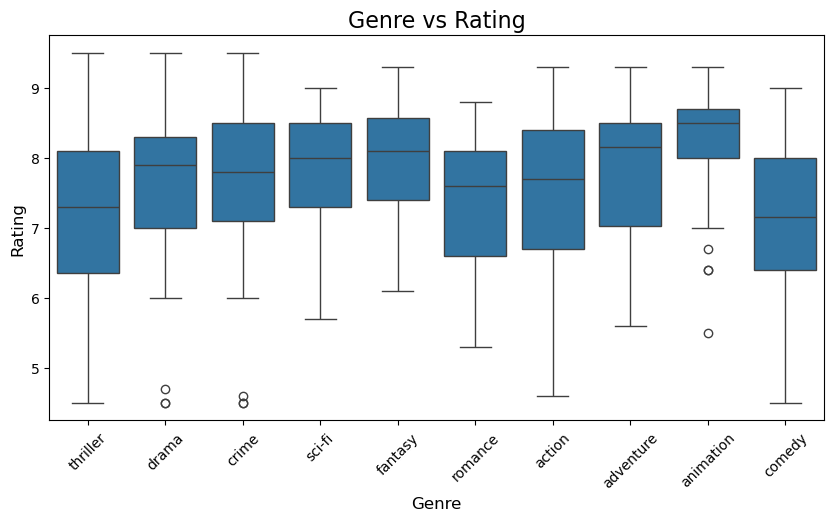

In [52]:
plt.figure(figsize=(10,5))
sns.boxplot(data=dfb, x="Genre", y="Rating")
plt.title("Genre vs Rating",fontsize=16)
plt.xlabel("Genre",fontsize=12)
plt.ylabel("Rating",fontsize=12)
plt.xticks(rotation=45)
plt.show()

**Insights**
1. Which genre has the highest median rating?
2. Which genre has the widest spread of ratings?
3. Which genre is most consistent?
4. Which genres contain exceptionally high rated titles(outliers)?

**Observations**

* **Animation** has the highest median rating (around 8.5), indicating that animated titles tend to receive the strongest audience ratings.
* **Comedy** and **Thriller** have comparatively lower median ratings, suggesting these genres receive lower audience ratings on average.
* **Action** and **Thriller** show the widest spread of ratings (largest overall range), indicating greater variability in audience reception.
* **Animation** has a relatively narrow box (small IQR), making it one of the most consistent genres in terms of ratings.
* Most genres have median ratings above 7.0, indicating generally positive audience reception across the dataset.
* **Drama**, **Crime**, and **Adventure** contain a few unusually low-rated titles, visible as outliers below the lower whiskers.
* Several genres reach ratings above 9.0, showing that highly rated titles are present across multiple genres.

**Conclusion**
> Animation emerges as the highest-rated and most consistent genre, while Action and Thriller exhibit greater variation in ratings. Overall, most genres receive favorable ratings, with median ratings generally above 7.0.


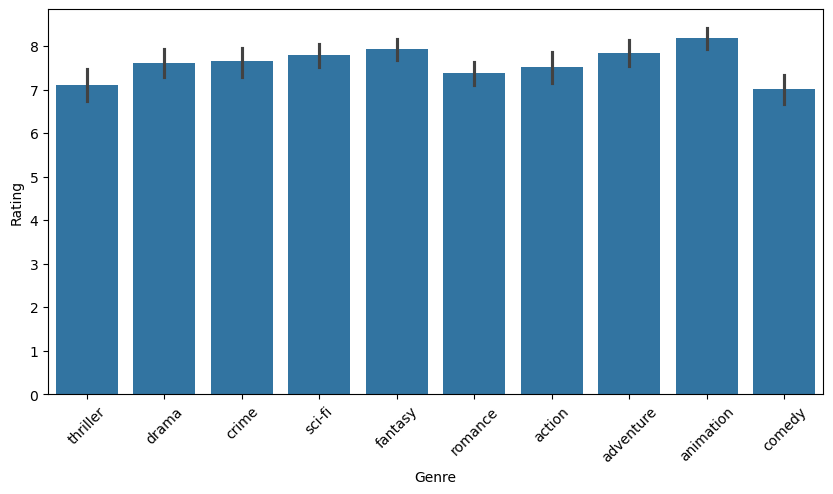

In [53]:
plt.figure(figsize=(10,5))

sns.barplot(data=dfb, x="Genre", y="Rating")

plt.xticks(rotation=45)
plt.show()

#### Genre vs Runtime

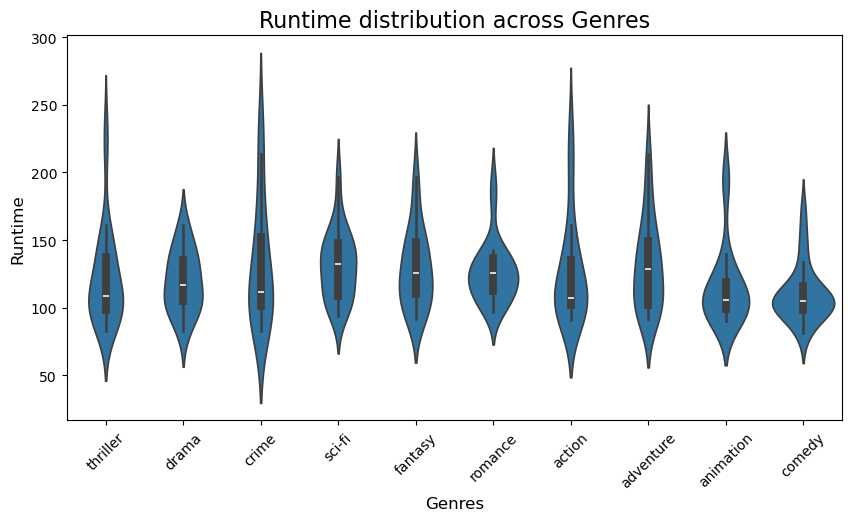

In [54]:
plt.figure(figsize=(10,5))
sns.violinplot(data=dfb, x="Genre", y="Runtime")
plt.xlabel("Genres",fontsize=12)
plt.ylabel("Runtime",fontsize=12)
plt.xticks(rotation=45)
plt.title("Runtime distribution across Genres",fontsize=16)
plt.show()

**Insights**
Do certain genres tend to have longer runtimes than others?

**Observations**
- Runtime distributions vary across genres, indicating that some genres tend to have longer movies than others.
- **Sci-fi, Fantasy, Adventure, and Romance** generally show higher median runtimes, suggesting that titles in these genres tend to be longer.
- **Comedy** has one of the lowest median runtimes and a relatively narrow distribution, indicating that comedy titles are generally shorter and more consistent in length.
- **Action, Crime, and Adventure** exhibit wider runtime distributions, showing greater variation in movie lengths within these genres.
-  Several genres display long upper tails extending beyond 180–200 minutes, indicating the presence of a few exceptionally long titles.
- The thicker portions of each violin represent where runtimes are most concentrated. For most genres, runtimes cluster around **100–140 minutes**.

**Conclusion**
> Most genres have typical runtimes between 100 and 140 minutes. Sci-fi, Fantasy, Adventure, and Romance tend to have longer runtimes, while Comedy generally contains shorter and more consistent-length titles. Action, Crime, and Adventure show greater variability in runtime compared to other genres.

> Runtime-related observations are based on 212 available records and should be interpreted with caution due to missing runtime information for a substantial portion of the dataset.




In [55]:
# plt.figure(figsize=(10,5))

# sns.stripplot(data=dfb, x="Genre", y="Rating")

# plt.xticks(rotation=45)
# plt.show()

In [56]:
# plt.figure(figsize=(10,5))

# sns.swarmplot(data=dfb, x="Genre", y="Rating")

# plt.xticks(rotation=45)
# plt.show()

#### Genre vs Metascore

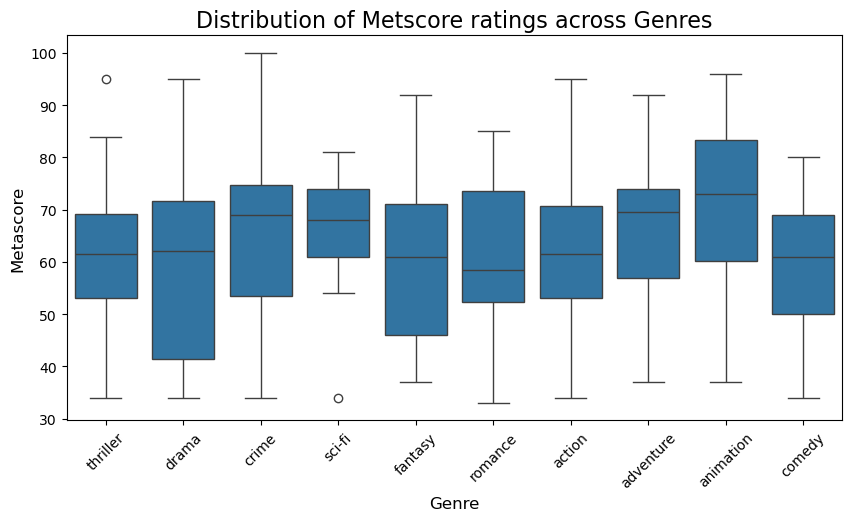

In [57]:
plt.figure(figsize=(10,5))
sns.boxplot(data=dfb, x="Genre", y="Metascore")
plt.xlabel("Genre",fontsize=12)
plt.ylabel("Metascore",fontsize=12)
plt.xticks(rotation=45)
plt.title("Distribution of Metscore ratings across Genres",fontsize=16)
plt.show()

In [58]:
dfb.groupby("Genre")["Metascore"].count()

Genre
action       16
adventure    18
animation    18
comedy       22
crime        12
drama        10
fantasy      13
romance      20
sci-fi       17
thriller     20
Name: Metascore, dtype: int64

**Insights**
Do  critics rate some genres more favourably than others?

**Observations**

- **Animation** has the highest median Metascore (around 73), suggesting that animated titles generally receive stronger critic reviews than other genres.
- **Adventure, Crime, and Sci-fi** also show relatively high median Metascores, indicating favorable critical reception.
- **Romance** has one of the lowest median Metascores, suggesting comparatively weaker critic ratings.
- Most genres have median Metascores between **58 and 70**, indicating moderate to positive critic evaluations across the dataset.
- **Drama** exhibits a wider interquartile range (IQR), suggesting greater variability in critic ratings within the genre.
- The distributions for **Animation** and **Sci-fi** appear relatively compact, indicating more consistency in critic scores.
- A few outliers are visible, such as a high Metascore title in **Thriller** and a low Metascore title in **Sci-fi**, showing that some titles perform substantially differently from the rest of their genre.

**Conclusion**
> Animation appears to be the most highly rated genre from a critic perspective, while Romance tends to receive lower Metascores. Most genres receive moderate to favorable critic reviews, although variability differs across genres. Since Metascore data is available for a limited number of titles, these findings should be interpreted with caution.



#### Genre vs Votes_K

<Figure size 1000x500 with 0 Axes>

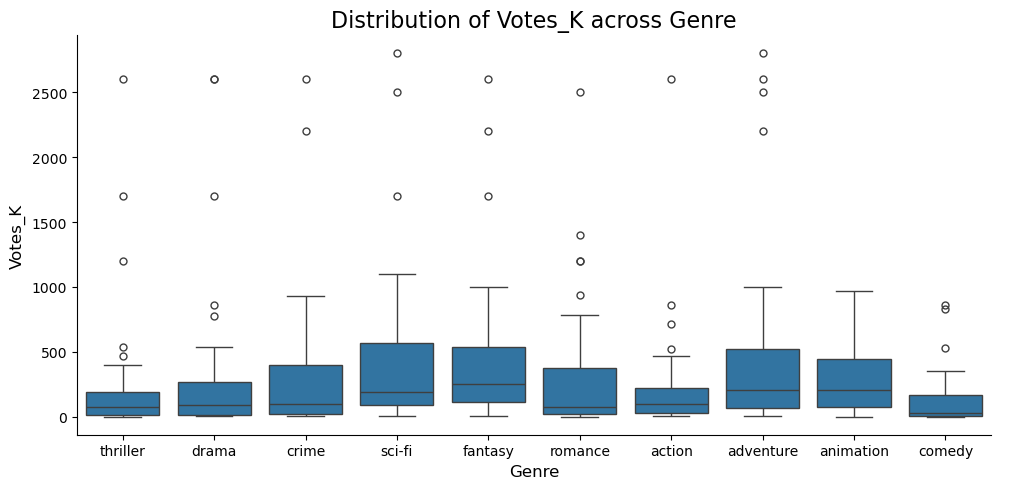

In [59]:
plt.figure(figsize=(10,5))
sns.catplot(
    data=dfb,
    x="Genre",
    y="Votes_K",
    kind="box",   #violin,bar
    height=5,
    aspect=2
)
plt.title("Distribution of Votes_K across Genre",fontsize=16)
plt.xlabel("Genre",fontsize=12)
plt.ylabel("Votes_K",fontsize=12)
plt.tight_layout()
plt.show()

**Insights**
What genres attract the highest audience engagement?

**Observations**

- **Fantasy, Sci-fi, Adventure, and Animation** have the highest median vote counts, indicating that these genres generally attract greater audience engagement.
- **Comedy, Drama, and Thriller** show comparatively lower median vote counts, suggesting lower audience engagement on average.
- **Sci-fi, Fantasy, and Adventure** exhibit a wider spread of votes (larger IQRs), indicating substantial variation in popularity among titles within these genres.
- Most genres contain several high-vote outliers, showing that a few exceptionally popular titles attract significantly more audience attention than the majority of titles.
- The highest outliers (above 2,000K votes) are observed in genres such as **Crime, Fantasy, and Adventure**, indicating the presence of extremely popular titles.
- **Comedy** has one of the lowest median vote counts and a relatively compact distribution, suggesting more consistent but lower audience engagement.

**Conclusion**
> Audience engagement varies across genres, with Fantasy, Sci-fi, Adventure, and Animation generally attracting higher vote counts.
> While most genres contain a few exceptionally popular titles, Comedy, Drama, and Thriller tend to receive lower audience engagement overall.
> The presence of several extreme outliers suggests that a small number of highly popular titles significantly influence audience participation within certain genres.


#### Certificate vs Rating

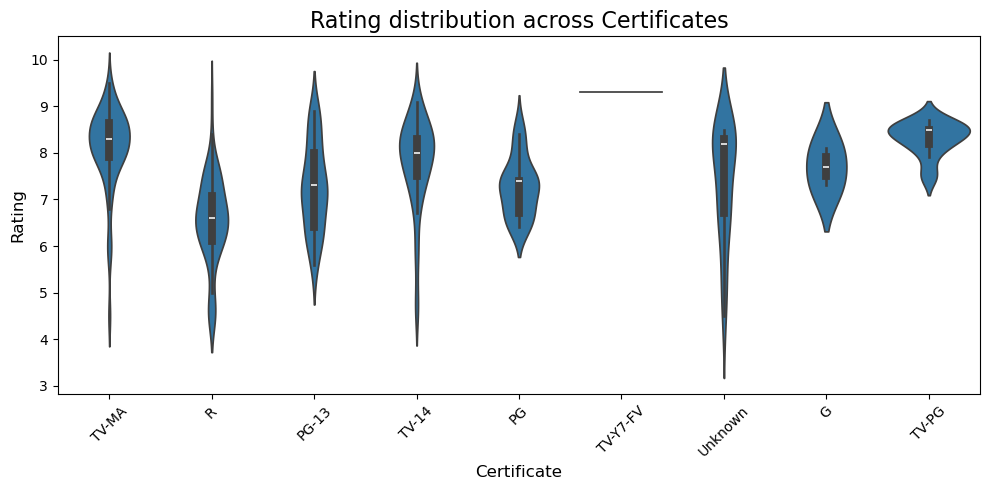

In [60]:
# Certificate vs Rating
plt.figure(figsize=(10,5))
sns.violinplot(data=dfb, x="Certificate", y="Rating")
plt.xticks(rotation=45)
plt.title("Rating distribution across Certificates",fontsize=16)
plt.xlabel("Certificate",fontsize=12)
plt.ylabel("Rating",fontsize=12)
plt.tight_layout()
plt.show()

**Insights**
How IMDb ratings are distributed across different certification categories?

**Observations**

- **TV-PG** and **TV-Y7-FV** show the highest median ratings, indicating that titles in these categories tend to receive strong audience ratings. However, these categories appear to contain very few titles, so conclusions should be interpreted cautiously.
- **TV-MA** and **TV-14** also have relatively high median ratings, suggesting that these certifications generally perform well among audiences.
- **R-rated** titles have one of the lowest median ratings and exhibit substantial variability in ratings.
- Most certificate categories have ratings concentrated between **6.5 and 8.5**, indicating generally positive audience reception.
- **TV-MA**, **TV-14**, and **PG-13** display wider distributions, suggesting greater variation in ratings within these categories.
- Some certifications show long lower tails, indicating the presence of a few poorly rated titles despite having strong overall ratings.

**Conclusion**
> Audience ratings vary across certification categories, with TV-PG, TV-Y7-FV, TV-MA, and TV-14 generally receiving higher ratings. R-rated titles tend to have lower median ratings and greater variability. However, categories with very small sample sizes should be interpreted cautiously, as a few titles can significantly influence the observed distribution.
> Certifications such as **G (2 titles)** and **TV-Y7-FV (4 titles)** contain very few observations. Therefore, their high ratings may not be representative of the broader population and should be interpreted with caution.

#### Certificate vs Runtime

<Figure size 1000x500 with 0 Axes>

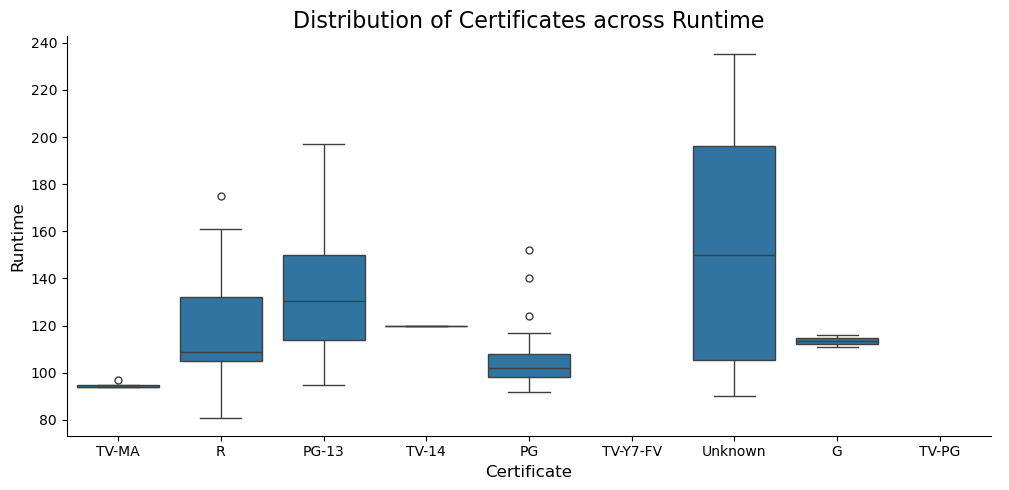

In [61]:
# Certificate vs runtime
# Do titles with diff certificateion categoires tend to have diff runtimes
# boxplot or violin plot
plt.figure(figsize=(10,5))
sns.catplot(
    data=dfb,
    x="Certificate",
    y="Runtime",
    kind="box",   #violin,bar
    height=5,
    aspect=2
)
plt.title("Distribution of Certificates across Runtime",fontsize=16)
plt.xlabel("Certificate",fontsize=12)
plt.ylabel("Runtime",fontsize=12)
plt.tight_layout()
plt.show()

**Insights**
Do titles with diff certificateion categoires tend to have diff runtimes?

**Observations**
- **Unknown** certificates have the highest median runtime and the widest spread, indicating substantial variation in movie lengths within this category.
- **PG-13** titles generally have longer runtimes, with a median runtime around 130 minutes.
- **TV-14** titles show a fairly consistent runtime around 120 minutes with relatively little variation.
- **PG** titles tend to have shorter runtimes, with most movies clustered around 95–110 minutes.
- **R-rated** titles exhibit considerable variability in runtime, ranging from relatively short to very long movies.
- Several certificate categories contain high-runtime outliers, suggesting the presence of a few exceptionally long titles.
- Most certificate categories have typical runtimes between **100 and 150 minutes**.

**Conclusion**
> Runtime varies across certification categories. PG-13 and Unknown-certified titles generally have longer runtimes, while PG titles tend to be shorter. R-rated movies show the greatest variation in length, indicating a wider diversity of content duration within that category.
> Some certificate categories contain very few titles, so their runtime distributions may not be representative of the broader population.


#### Certificate vs Metascore

<Figure size 1000x500 with 0 Axes>

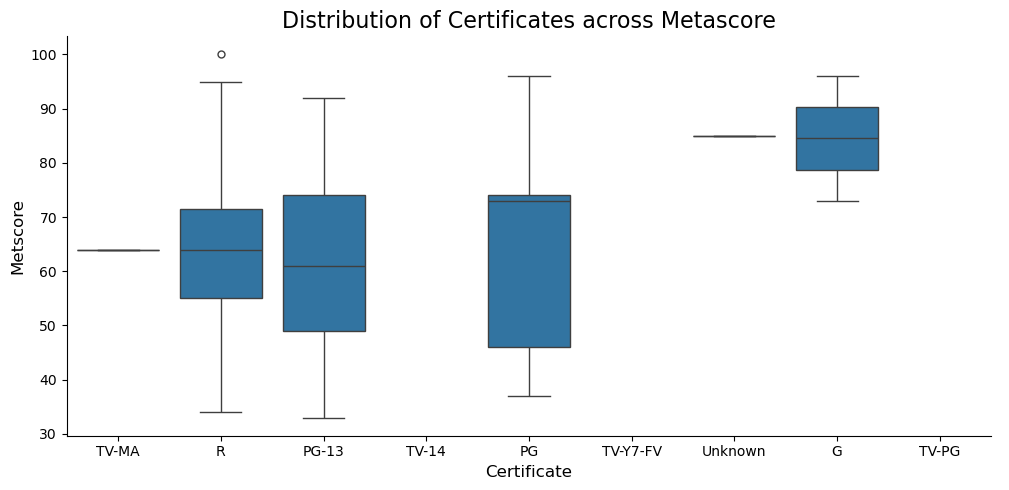

In [62]:
# Certificate vs Metscoer
# Do critics rate certain certification categories more favourably than others ?
plt.figure(figsize=(10,5))
sns.catplot(
    data=dfb,
    x="Certificate",
    y="Metascore",
    kind="box",   #violin,bar
    height=5,
    aspect=2
)
plt.title("Distribution of Certificates across Metascore",fontsize=16)
plt.xlabel("Certificate",fontsize=12)
plt.ylabel("Metscore",fontsize=12)
plt.tight_layout()
plt.show()

**Insights**
 Do critics rate certain certification categories more favourably than others ?

**Observations**
- **G-rated** titles have the highest median Metascore (around 85), indicating strong critical reception. However, this category contains very few titles.
- **PG** and **R-rated** titles show a wide spread of Metascores, suggesting substantial variation in critic reviews within these categories.
- **PG-13** titles have a moderate median Metascore (around 60) and exhibit considerable variability in critic scores.
- Most certificate categories have Metascores ranging between **50 and 80**, indicating generally average to favorable critic evaluations.
- **PG** displays one of the widest distributions, implying that critic reception varies significantly across PG-certified titles.
- Some categories such as **TV-MA, TV-14, Unknown, and TV-Y7-FV** appear to have very few observations, resulting in limited or no visible distribution.

**Conclusion**
> Critic ratings vary across certification categories, with G-rated titles showing the highest Metascores in this dataset. PG and R-rated titles exhibit the greatest variability in critic reviews, while most certificates receive moderate to favorable Metascores overall. However, due to the limited number of observations in several categories, these findings should be interpreted cautiously.
> Metascore data is available for only a subset of titles, and some certificate categories contain very few observations. Therefore, conclusions regarding critic ratings across certifications may not fully represent the broader dataset.



#### Certificate vs Votes_K

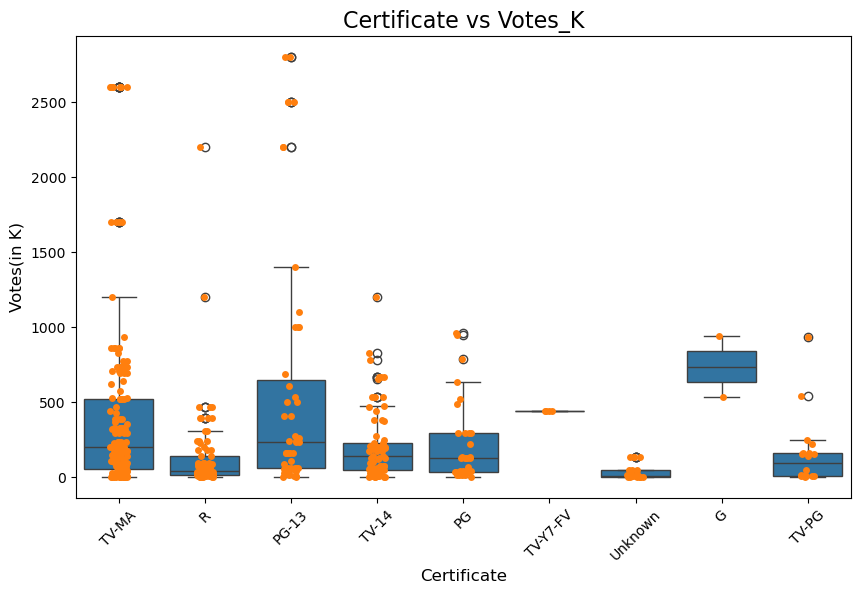

In [63]:
# Certificate vs Votes
# Do certain certification categories attract more audience engagement tahn others?
# Strip + box

plt.figure(figsize=(10,6))
sns.boxplot(data=dfb, x="Certificate", y="Votes_K")
sns.stripplot(data=dfb, x="Certificate", y="Votes_K", jitter=True)
plt.title("Certificate vs Votes_K",fontsize=16)
plt.xlabel("Certificate",fontsize=12)
plt.ylabel("Votes(in K)",fontsize=12)
plt.xticks(rotation=45)
plt.show()

**Insights**
Do certain certification categories attract more audience engagement than others?

**Observations**

- **TV-MA** and **PG-13** contain several of the highest-voted titles, with some exceeding **2,000K votes**, indicating exceptionally high audience engagement.
- Most titles across all certificate categories receive fewer than **500K votes**, showing that highly popular titles are relatively rare.
- **TV-MA** exhibits the widest spread of vote counts, suggesting large variation in audience engagement within this category.
- **PG-13** also shows substantial variability, ranging from very low vote counts to some of the most popular titles in the dataset.
- **R** and **TV-14** categories contain a mix of low- and moderate-engagement titles, along with a few highly popular outliers.
- Categories such as **G**, **TV-Y7-FV**, **TV-PG**, and **Unknown** contain relatively few observations, making it difficult to draw strong conclusions about their audience engagement patterns.

**Conclusion**
> Audience engagement varies considerably across certification categories. TV-MA and PG-13 contain several of the most popular titles in the dataset, while most titles across all certifications receive comparatively lower vote counts. The presence of numerous extreme outliers suggests that a small number of highly successful titles contribute disproportionately to overall audience engagement.
> Vote distributions are strongly right-skewed, with a few extremely popular titles receiving substantially more votes than the majority of titles. Therefore, median values may provide a more representative measure of audience engagement than mean values.


#### Year vs Rating

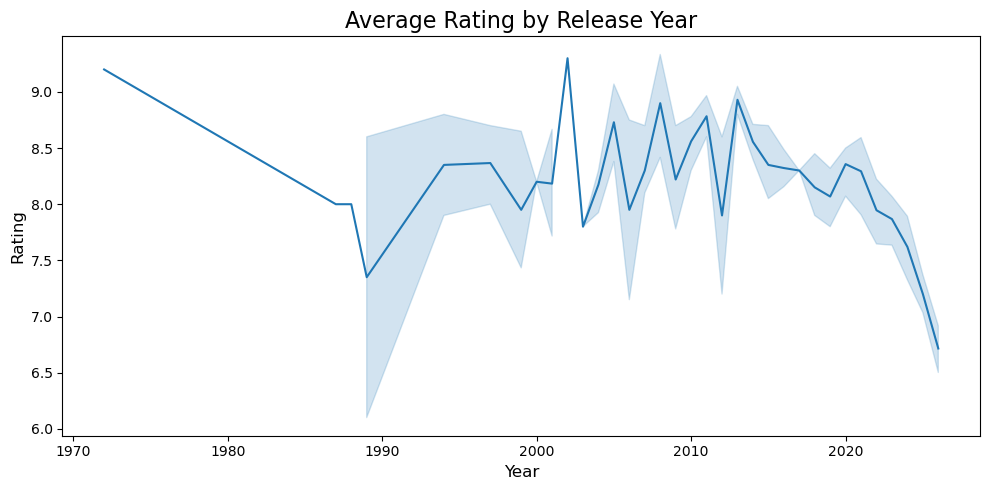

In [64]:
plt.figure(figsize=(10,5))
sns.lineplot(
    data=dfb,
    x="Year",
    y="Rating",
    estimator="mean"
)
plt.title("Average Rating by Release Year",fontsize=16)
plt.xlabel("Year",fontsize=12)
plt.ylabel("Rating",fontsize=12)
plt.tight_layout()
plt.show()

**Insights**

**Observations**
- The average IMDb rating varies across release years, ranging approximately from 6.7 to 9.3.
- The highest average rating is observed around 2002, at approximately 9.3.
- Older titles (1972–1989) generally have high average ratings, mostly between 8.0 and 9.2, although these years contain very few titles.
- Between 2005 and 2015, average ratings remain consistently high, generally ranging from 8.0 to 8.9.
- From 2020 onwards, the average rating shows a gradual decline, reaching approximately 6.7 by 2026.
- The wider confidence intervals in some years indicate greater variability in ratings or fewer observations for those years.

**Conclusion**
>The analysis suggests that average IMDb ratings have remained relatively high over the years, particularly between 2005 and 2015. However, more recent years, especially 2025–2026, exhibit comparatively lower average ratings. Since several years contain only a small number of titles, these yearly averages should be interpreted with caution.Some release years contain only a few titles. Therefore, average ratings and vote counts for those years may be influenced by small sample sizes and should be interpreted cautiously.

#### Year vs Votes_K

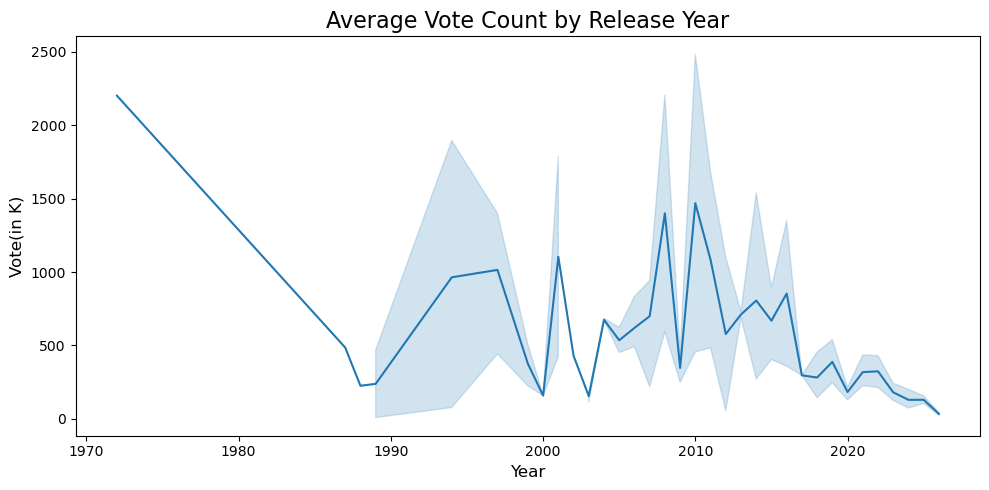

In [65]:
plt.figure(figsize=(10,5))
sns.lineplot(
    data=dfb,
    x="Year",
    y="Votes_K",
    estimator="mean"
)
plt.title("Average Vote Count by Release Year",fontsize=16)
plt.xlabel("Year",fontsize=12)
plt.ylabel("Vote(in K)",fontsize=12)
plt.tight_layout()
plt.show()

**Insights**

**Observations**
- Average audience vote counts vary considerably across release years, ranging from approximately 50K to over 2200K votes.
- The highest average vote count is observed for 1972, at around 2200K votes, though this year contains only a single title.
- Another peak occurs around 2009–2010, where average vote counts reach approximately 1400–1500K.
- Between 2005 and 2017, several years maintain relatively high audience engagement, with average vote counts generally exceeding 500K.
- From 2018 onwards, average vote counts decline steadily, falling below 300K in recent years and reaching around 50K by 2026.
- The large confidence intervals in certain years indicate greater variation in vote counts or limited observations.

**Conclusion**
>The analysis indicates that audience engagement has generally declined for more recent release years. Older and established titles have accumulated substantially higher vote counts than recent releases, likely because they have been available to audiences for a longer period. Consequently, vote counts for recent years should be interpreted carefully, as newer titles have had less time to accumulate audience votes.Some release years contain only a few titles. Therefore, average ratings and vote counts for those years may be influenced by small sample sizes and should be interpreted cautiously.

# Conclusion Of Bivariate Analysis

- The bivariate analysis helped identify relationships between pairs of variables in the IMDb dataset.
- Genre and certificate were found to influence IMDb ratings, runtime, metascore, and audience vote counts.
- Adventure, Animation, Fantasy, and Sci-fi generally achieved higher ratings and audience engagement, while Comedy and some R-rated titles showed comparatively lower performance.
- Correlation analysis indicated positive relationships among ratings, metascores, runtime, and vote counts, suggesting that highly rated titles often receive better critic scores and greater audience engagement.
- Overall, the analysis provided valuable insights into how different variables are associated with one another, helping to better understand the factors influencing title quality, popularity, and audience reception.
